# 01. Data: five public sources joined on one river network

**Question for the project:** what drives the ecological health of England's rivers? How much is
storm overflow spills, how much sewage works, farming and towns? And where would cutting spills do most good?

The unit of analysis is the **WFD river water body**: 3,772 stretches of river in England, each with its
own land catchment and its own 2025 classification (Cycle 4).

| Source (all Environment Agency or Natural England) | Used for |
|---|---|
| WFD Cycle 4 2025 classification, catchment polygons and centrelines | targets, river typology, the river network |
| Event Duration Monitoring storm overflow annual returns 2020-2025 | spill counts and hours for ~14,000 overflows |
| Consented discharges to controlled waters (permit register) | sewage works and their dry-weather flow; private sewage; trade effluent |
| Living England Habitat Map Phase 4 | land cover of every catchment |
| Water Quality Archive (new API, 2023-2025) | measured phosphate, ammonia, BOD, nitrate, oxygen |
| Reasons for Not Achieving Good status (Cycle 3) | **validation only**: the EA's own investigation of why each water body fails |

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

## Storm overflow returns: six workbooks, five layouts, one tidy table

In [2]:
edm = pd.read_parquet(ROOT / "data/processed/edm_2020_2025.parquet")
summary = edm.groupby("year").agg(overflows=("company", "size"), spills=("spills", "sum"),
                                  spill_hours=("duration_hrs", "sum"),
                                  median_monitoring_pct=("edm_pct", "median"))
summary.round(0)

,overflows,spills,spill_hours,median_monitoring_pct
year,,,,
2020,12788,403722.0,3104817.0,100.0
2021,14470,372525.0,2667445.0,100.0
2022,14580,301091.0,1754921.0,100.0
2023,14530,464056.0,3606170.0,100.0
2024,14285,450398.0,3614428.0,100.0
2025,14303,292119.0,1878240.0,100.0


Each year's workbook differs: the header row moves, durations switch from decimal hours (2020-23) to
`hh:mm:ss` text and Excel datetimes (2024-25), water body IDs move from Cycle 2 to Cycle 3, and 2020 has no
grid references. `river_health.edm` standardises them. The 2023-2025 totals reproduce the Environment
Agency's published national figures to the hour (see `scripts/validate.py`).

In [3]:
v = pd.read_csv(T / "validation_checks.csv")
v[v.check.str.startswith("EDM")]

,check,passed,detail
0,EDM 2023 totals match EA published figures,True,"spills 464,056 vs 464,056; hours 3,606,170 vs ..."
1,EDM 2024 totals match EA published figures,True,"spills 450,398 vs 450,398; hours 3,614,428 vs ..."
2,EDM 2025 totals match EA published figures,True,"spills 292,119 vs 292,119; hours 1,878,240 vs ..."


## Building the river network

Pressures upstream travel downstream, so a water body's health depends on everything above it. The EA
publishes centrelines and catchments but **no downstream link**. We infer one from geometry: EA centrelines
are digitised in the direction of flow, so each line part's last vertex is a potential outlet; where it
touches another water body's line (not at that line's own end), that water body is downstream.
Gaps in the simplified geometry fall back to the nearest neighbouring catchment polygon.

In [4]:
e = pd.read_csv(ROOT / "data/processed/network_edges.csv")
print(e.rule.value_counts().to_string())
v[v.check.str.contains("network")][["check", "passed", "detail"]].style.hide(axis="index")

rule
line             3171
sea               509
polygon            71
cycle_dropped      21


check,passed,detail
inferred network: upstream areas within 25% of NRFA gauged areas (England-only data; Welsh headwaters missing),True,"Trent at North Muskham 8,240/8,231 km2; Tyne at Bywell 2,207/2,176 km2; Thames at Kingston 9,001/9,948 km2; Eden at Sheepmount 2,270/2,287 km2; Nene at Orton 1,576/1,634 km2"
river network is acyclic,True,"3772 links: {'line': 3171, 'sea': 509, 'polygon': 71, 'cycle_dropped': 21}"


Upstream areas reproduce the National River Flow Archive's gauged areas: Trent 8,240 vs 8,231 km²,
Eden 2,270 vs 2,287 km², Tyne 2,207 vs 2,176 km². The Thames reaches 9,001 of 9,948 km² because a few
links are lost in the simplified geometry. Rivers rising in Wales (Severn, Wye, Dee) are missing their
Welsh headwaters, which are outside the EA data.

In [5]:
t.nlargest(8, "up_area_km2")[["name", "up_area_km2", "n_upstream_wbs", "up_n_overflows", "up_n_stw"]].round(0)

,name,up_area_km2,n_upstream_wbs,up_n_overflows,up_n_stw
1564,Trent from Carlton-on-Trent to Laughton Drain,9677.0,288,1748.0,389.0
1174,Thames (Egham to Teddington),9001.0,251,268.0,270.0
2541,Ouse from R Wharfe to Upper Humber,8315.0,284,1401.0,350.0
2130,Trent from Soar to The Beck,8240.0,245,1622.0,323.0
534,Severn (E Channel) - Horsebere Bk to Severn Est,7816.0,228,576.0,403.0
3053,Severn - conf R Avon to conf Upper Parting,7697.0,221,566.0,403.0
813,Thames (Cookham to Egham),7254.0,207,215.0,242.0
2092,Thames (Reading to Cookham),6859.0,193,205.0,235.0


## The targets and the pressures on a map

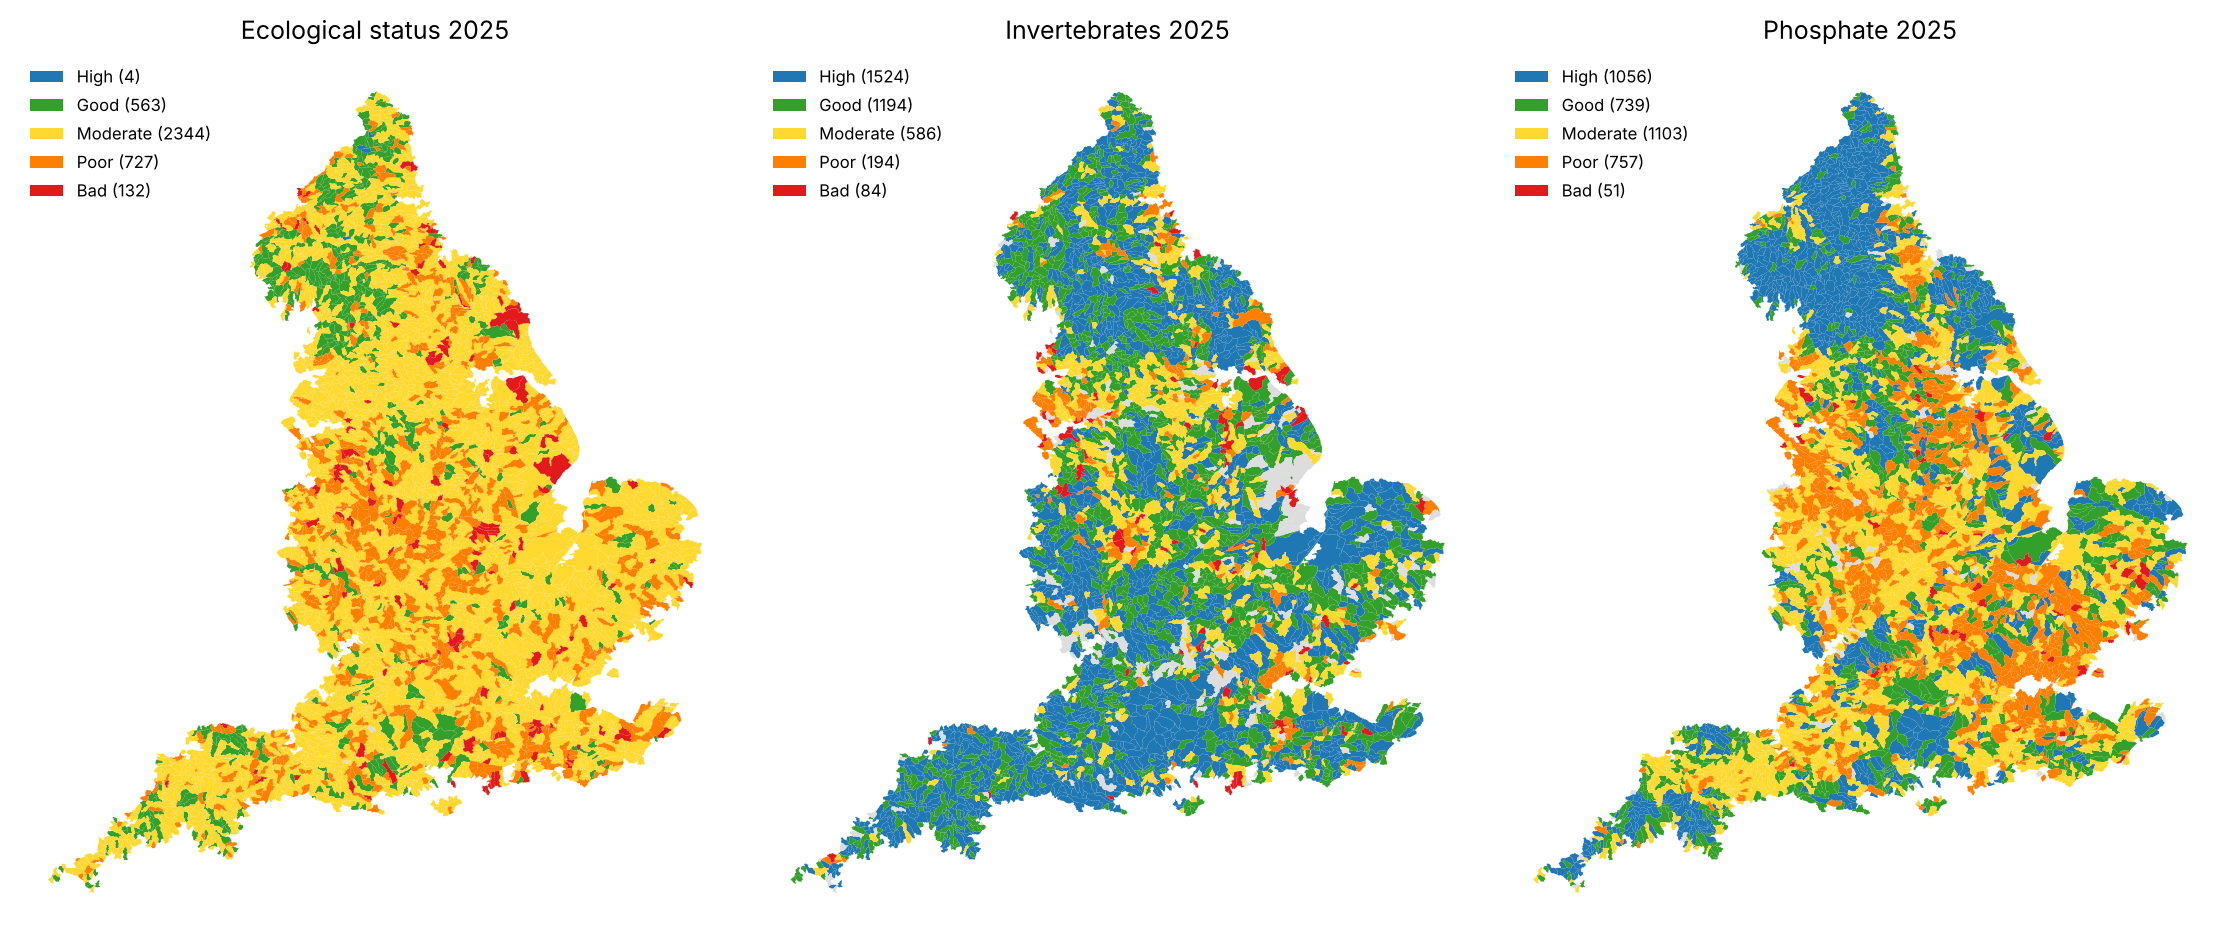

In [6]:
display(Image(FIG / "map_status.png"))

Only **15%** of river water bodies reach good ecological status. WFD status is *one out, all out*:
the worst element sets the overall class. Invertebrates mostly pass (76% good or high);
phosphate fails in half the water bodies, concentrated in the Midlands and the south-east.

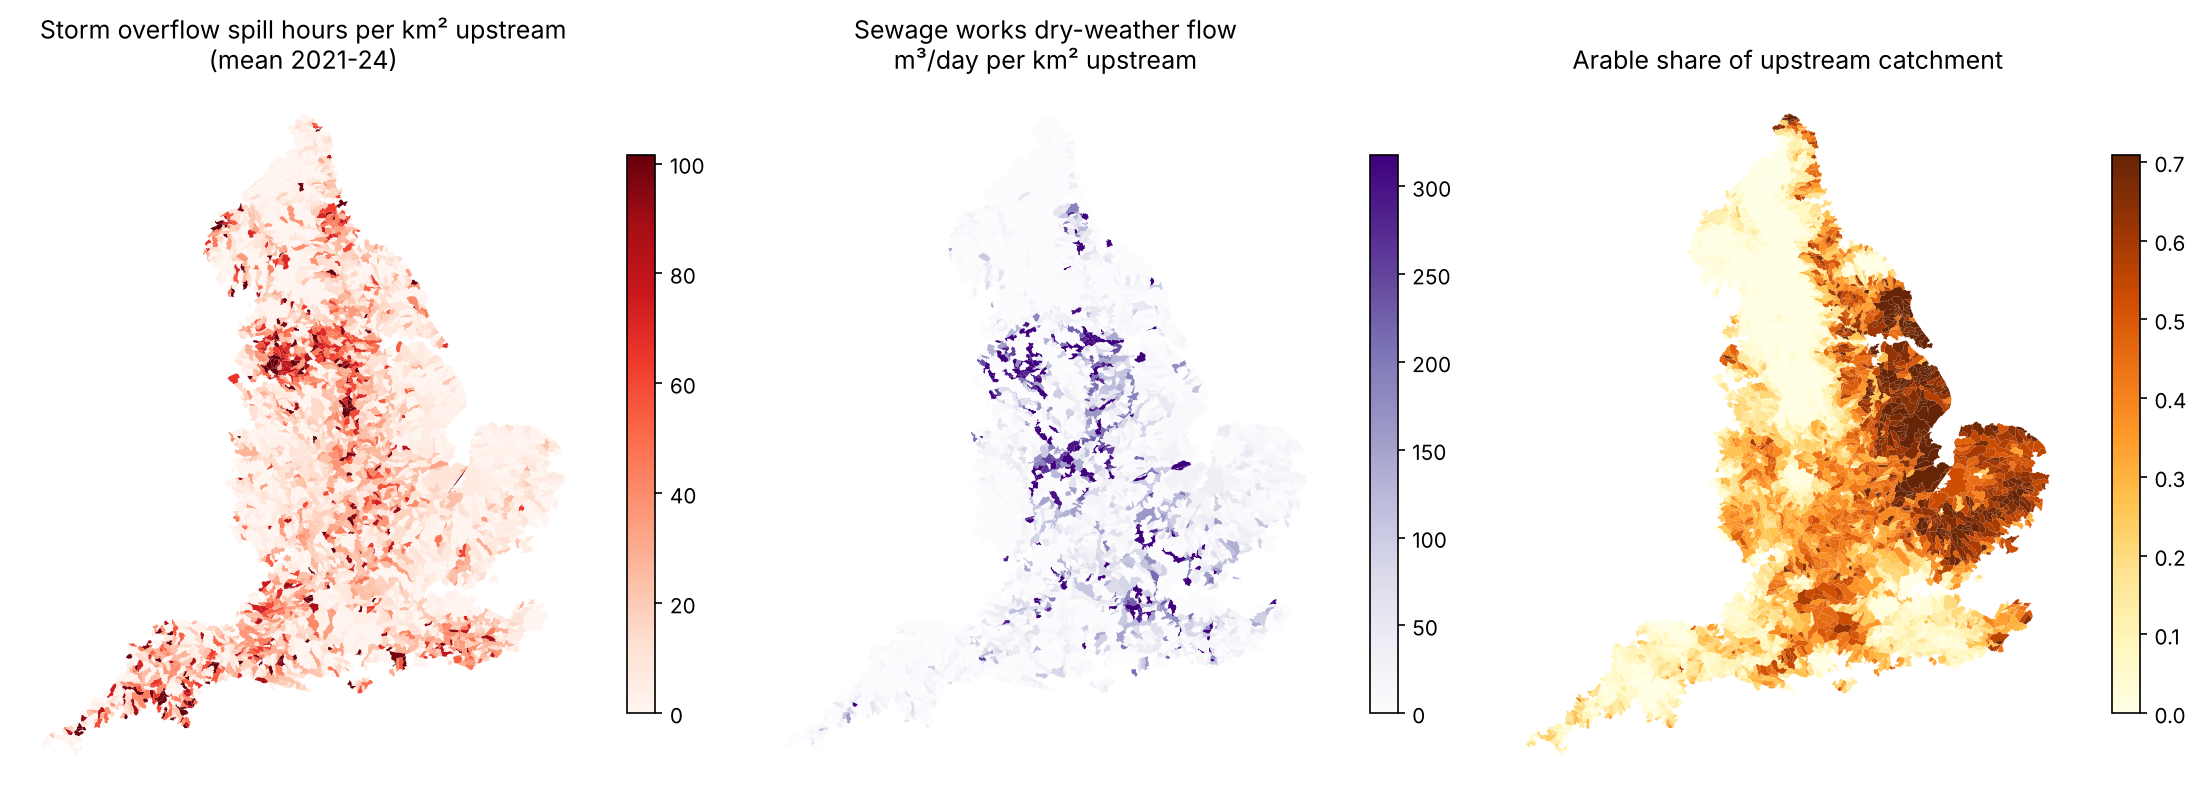

In [7]:
display(Image(FIG / "map_pressures.png"))

In [8]:
cov = pd.DataFrame({
    "linked overflows (2024)": [t.local_n_overflows.sum()],
    "water bodies with an overflow upstream": [(t.up_n_overflows > 0).mean()],
    "water bodies with a sewage works upstream": [(t.up_n_stw > 0).mean()],
    "water bodies with chemistry (>= 6 samples)": [t.chem_orthophosphate_mgP.notna().mean()],
}).T.rename(columns={0: "value"})
cov

,value
linked overflows (2024),11952.000000
water bodies with an overflow upstream,0.696978
water bodies with a sewage works upstream,0.646341
water bodies with chemistry (>= 6 samples),0.723489
